# Task 1: Clean and explore the energy dataset

**Goal.** One clean, documented hourly file (`clean_energy.csv`) that Tasks 2 and 3 can use, and an understanding of how household consumption behaves over the day, week and season.

**Dataset.** UCI *Individual Household Electric Power Consumption* (Hebrail and Berard): one house in France, one reading per minute, December 2006 to November 2010.

The cleaning code lives in `clean_energy.py`, so it can be re-run later on the data logged from the real ESP32 hardware.

In [1]:
import hashlib
import importlib
import subprocess
import sys
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Works when the notebook is opened from energy/ (or from the repository root)
REPO = Path.cwd().parent if Path.cwd().name == "energy" else Path.cwd()
UCI_FILE = REPO / "individual+household+electric+power+consumption" / "household_power_consumption.txt"
OUT = REPO / "energy"
assert UCI_FILE.exists(), f"raw file not found: {UCI_FILE}"

sys.path.insert(0, str(OUT))
import clean_energy as ce
importlib.reload(ce)

P = ce.TARGET
SUBS = ce.SUBS

## 1. Load the raw file

The file is semicolon-separated and uses `?` for missing values.

In [2]:
raw = ce.read_raw(UCI_FILE)
print("raw:", raw.shape, raw.index.min(), "->", raw.index.max())
print(raw.dtypes.to_string())

miss = raw.isna().sum()
print("\nMissing values per column:")
print(pd.DataFrame({"missing": miss, "pct": (miss / len(raw) * 100).round(2)}).to_string())
print("\nrows with at least one missing value:", int(raw.isna().any(axis=1).sum()),
      "| rows with every column missing:", int(raw.isna().all(axis=1).sum()))

raw: (2075259, 7) 2006-12-16 17:24:00 -> 2010-11-26 21:02:00
Global_active_power      float64
Global_reactive_power    float64
Voltage                  float64
Global_intensity         float64
Sub_metering_1           float64
Sub_metering_2           float64
Sub_metering_3           float64

Missing values per column:
                       missing   pct
Global_active_power      25979  1.25
Global_reactive_power    25979  1.25
Voltage                  25979  1.25
Global_intensity         25979  1.25
Sub_metering_1           25979  1.25
Sub_metering_2           25979  1.25
Sub_metering_3           25979  1.25

rows with at least one missing value: 25979 | rows with every column missing: 25979


## 2. Where are the missing values?

missing runs: 71 | longest (minutes): [7226, 5237, 3723, 3305, 3129] | runs longer than 3 hours: 7


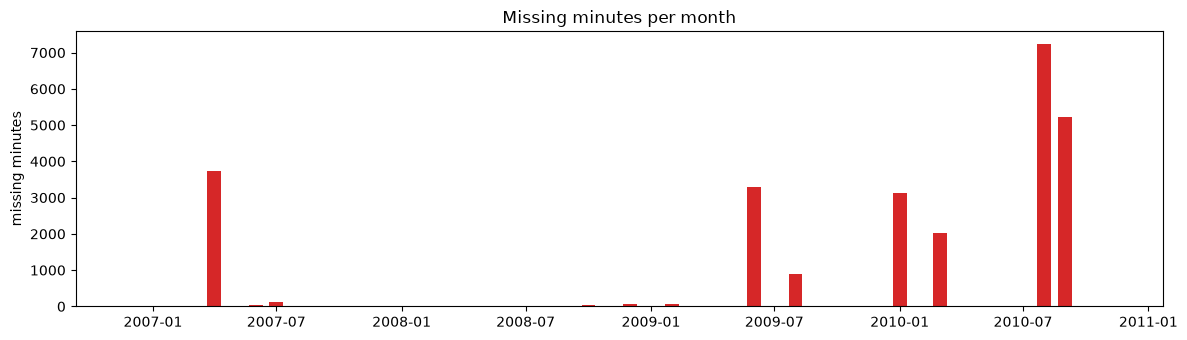

In [3]:
nan_min = raw[P].isna()
by_month = nan_min.groupby(raw.index.to_period("M")).sum()

run_id = (nan_min != nan_min.shift()).cumsum()
runs = nan_min.groupby(run_id).agg(["first", "size"])
gaps = runs.loc[runs["first"], "size"].sort_values(ascending=False)
print("missing runs:", len(gaps),
      "| longest (minutes):", gaps.head(5).tolist(),
      "| runs longer than 3 hours:", int((gaps > 180).sum()))

fig, ax = plt.subplots(figsize=(12, 3.5))
ax.bar(by_month.index.to_timestamp(), by_month.values, width=20, color="tab:red")
ax.set(title="Missing minutes per month", ylabel="missing minutes")
fig.tight_layout()
plt.show()

## 3. Clean: hourly means, short gaps filled, long gaps dropped, features added

Decisions:
- Minutes are averaged into hours. An hour without any reading stays missing.
- A missing run of up to 3 hours is forward-filled (a short gap, the last value is a fair guess). A longer run is dropped, because filling it would invent data.
- Features: `hour`, `weekday` (0 = Monday), `month`, `is_weekend`, and `unmetered`, the energy not covered by the three sub-meters (`Global_active_power * 1000 / 60 - Sub_metering_1 - Sub_metering_2 - Sub_metering_3`, in Wh per minute).

In [4]:
hourly, stats = ce.to_hourly(raw)
df = ce.add_features(hourly)

print(stats)
print(df.shape, df.index.min(), "->", df.index.max())
print("nulls:", int(df.isna().sum().sum()), "| duplicate timestamps:", int(df.index.duplicated().sum()))
print("hours with unmetered < 0:", int((df["unmetered"] < 0).sum()))
print()
print(df.dtypes.to_string())
display(df.head(3))

{'raw_rows': 2075259, 'raw_missing_rows': 25979, 'hours_in_range': 34589, 'hours_without_data': 421, 'hours_filled': 1, 'hours_dropped': 420, 'hours_final': 34169}
(34169, 12) 2006-12-16 17:00:00 -> 2010-11-26 21:00:00
nulls: 0 | duplicate timestamps: 0
hours with unmetered < 0: 0

Global_active_power      float64
Global_reactive_power    float64
Voltage                  float64
Global_intensity         float64
Sub_metering_1           float64
Sub_metering_2           float64
Sub_metering_3           float64
unmetered                float64
hour                       int32
weekday                    int32
month                      int32
is_weekend                 int64


,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3,unmetered,hour,weekday,month,is_weekend
datetime,,,,,,,,,,,,
2006-12-16 17:00:00,4.222889,0.229000,234.643889,18.100000,0.0,0.527778,16.861111,52.992593,17,5,12,1
2006-12-16 18:00:00,3.632200,0.080033,234.580167,15.600000,0.0,6.716667,16.866667,36.953333,18,5,12,1
2006-12-16 19:00:00,3.400233,0.085233,233.232500,14.503333,0.0,1.433333,16.683333,38.553889,19,5,12,1


In [5]:
assert df.isna().sum().sum() == 0
assert df.index.is_monotonic_increasing and not df.index.has_duplicates
assert all(pd.api.types.is_numeric_dtype(t) for t in df.dtypes)
print("OK: no missing values, sorted unique index, numeric columns")

display(df.describe().T.round(3))

OK: no missing values, sorted unique index, numeric columns


,count,mean,std,min,25%,50%,75%,max
Global_active_power,34169.0,1.092,0.898,0.124,0.342,0.803,1.579,6.561
Global_reactive_power,34169.0,0.124,0.067,0.000,0.078,0.107,0.149,0.774
Voltage,34169.0,240.839,3.001,225.834,239.181,240.978,242.695,251.902
Global_intensity,34169.0,4.628,3.758,0.503,1.513,3.423,6.607,28.383
Sub_metering_1,34169.0,1.122,3.538,0.000,0.000,0.000,0.000,48.367
Sub_metering_2,34169.0,1.299,4.193,0.000,0.000,0.333,0.650,46.433
Sub_metering_3,34169.0,6.459,7.351,0.000,0.650,1.650,14.217,21.550
unmetered,34169.0,9.316,8.273,1.379,4.357,5.755,11.113,64.837
hour,34169.0,11.505,6.925,0.000,6.000,12.000,18.000,23.000
weekday,34169.0,2.990,1.998,0.000,1.000,3.000,5.000,6.000


## 4. Explore: day, week and season

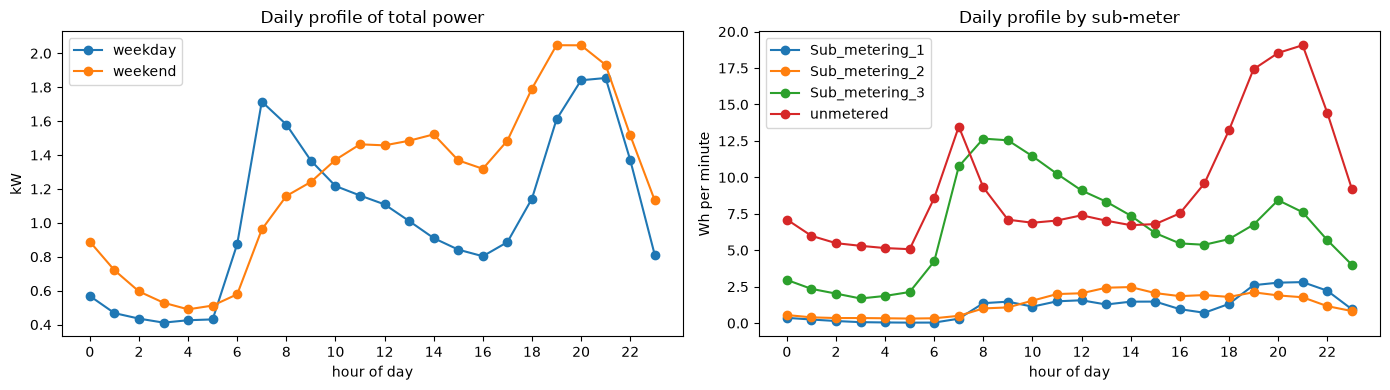

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

for wk, label in [(0, "weekday"), (1, "weekend")]:
    prof = df.loc[df["is_weekend"] == wk, P].groupby(df["hour"]).mean()
    axes[0].plot(prof.index, prof.values, marker="o", label=label)
axes[0].set(title="Daily profile of total power", xlabel="hour of day", ylabel="kW")
axes[0].set_xticks(range(0, 24, 2))
axes[0].legend()

df.groupby("hour")[SUBS + ["unmetered"]].mean().plot(ax=axes[1], marker="o")
axes[1].set(title="Daily profile by sub-meter", xlabel="hour of day", ylabel="Wh per minute")
axes[1].set_xticks(range(0, 24, 2))

fig.tight_layout()
plt.show()

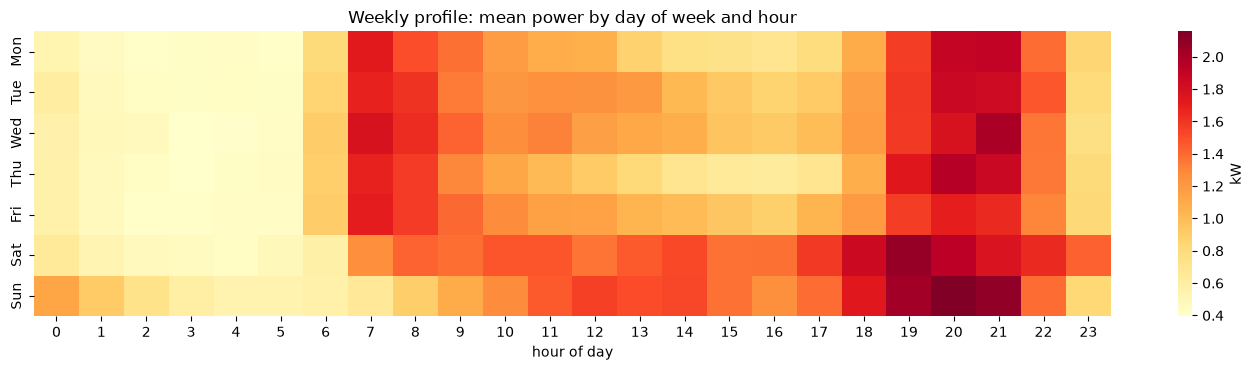

In [7]:
heat = df.pivot_table(values=P, index="weekday", columns="hour", aggfunc="mean")
heat.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"][: len(heat)]

fig, ax = plt.subplots(figsize=(14, 3.8))
sns.heatmap(heat, cmap="YlOrRd", ax=ax, cbar_kws={"label": "kW"})
ax.set(title="Weekly profile: mean power by day of week and hour", xlabel="hour of day", ylabel="")
fig.tight_layout()
plt.show()

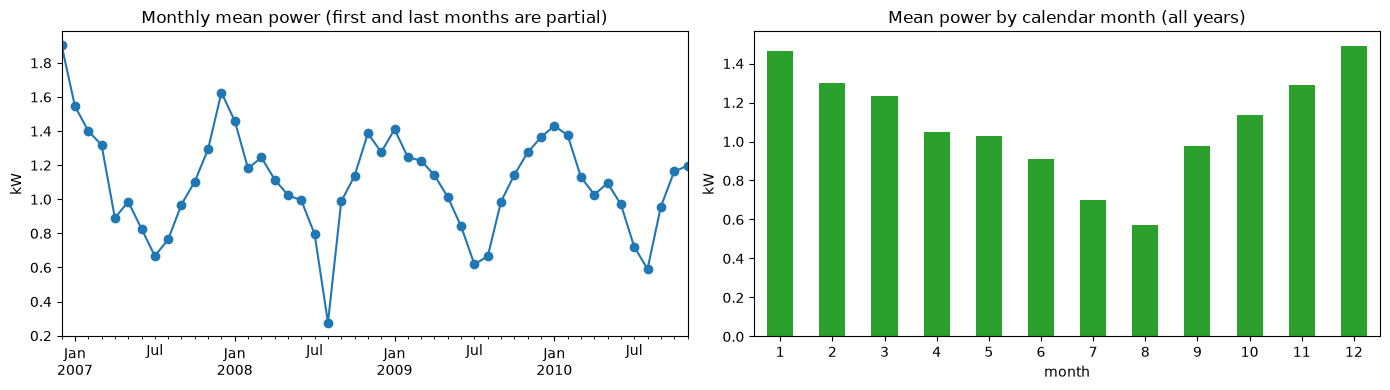

In [8]:
monthly = df[P].resample("MS").mean()
season = df[P].groupby(df["month"]).mean()

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
monthly.plot(ax=axes[0], marker="o")
axes[0].set(title="Monthly mean power (first and last months are partial)", xlabel="", ylabel="kW")

season.plot(kind="bar", ax=axes[1], color="tab:green")
axes[1].set(title="Mean power by calendar month (all years)", xlabel="month", ylabel="kW")
axes[1].tick_params(axis="x", rotation=0)

fig.tight_layout()
plt.show()

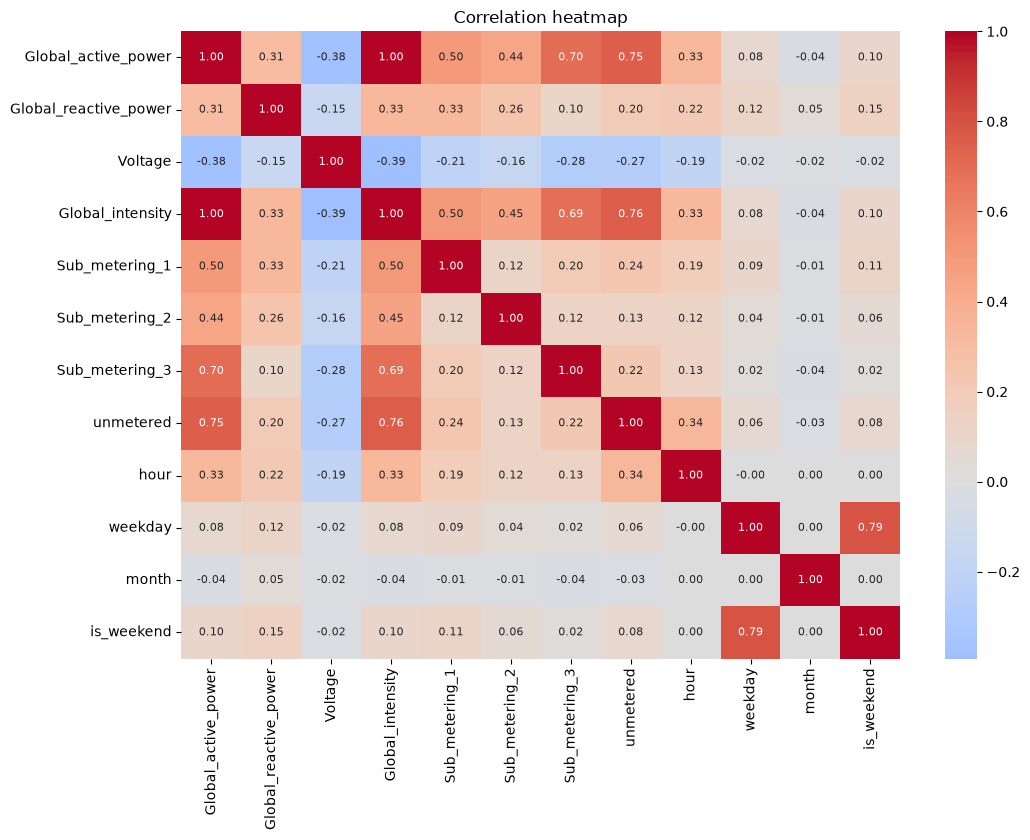

In [9]:
corr = df.corr()

fig, ax = plt.subplots(figsize=(11, 8.5))
sns.heatmap(corr, annot=True, fmt=".2f", annot_kws={"size": 8}, cmap="coolwarm", center=0, ax=ax)
ax.set_title("Correlation heatmap")
fig.tight_layout()
plt.show()

In [10]:
by_hour = df.groupby("hour")[P].mean()
wk = df.groupby("is_weekend")[P].mean()
mon = df.groupby("month")[P].mean()
winter = df.loc[df["month"].isin([12, 1, 2]), P].mean()
summer = df.loc[df["month"].isin([6, 7, 8]), P].mean()
total_wh = df[P] * 1000 / 60

print(f"overall mean power           : {df[P].mean():.3f} kW (highest hour {df[P].max():.2f} kW)")
print(f"peak hour of day             : {by_hour.idxmax():02d}:00  ({by_hour.max():.3f} kW)")
print(f"lowest hour of day           : {by_hour.idxmin():02d}:00  ({by_hour.min():.3f} kW)")
print(f"weekday vs weekend mean      : {wk[0]:.3f} vs {wk[1]:.3f} kW  (weekend / weekday = {wk[1] / wk[0]:.2f})")
print(f"winter (Dec-Feb) vs summer (Jun-Aug): {winter:.3f} vs {summer:.3f} kW  (winter / summer = {winter / summer:.2f})")
print(f"highest / lowest calendar month: {mon.idxmax()} ({mon.max():.3f}) / {mon.idxmin()} ({mon.min():.3f})")
print("share of total energy:")
for c in SUBS + ["unmetered"]:
    print(f"   {c:15s} {df[c].mean() / total_wh.mean() * 100:5.1f}%")
print(f"\ncorrelation with {P}:")
print(df.drop(columns=[P]).corrwith(df[P]).round(2).to_string())

overall mean power           : 1.092 kW (highest hour 6.56 kW)
peak hour of day             : 20:00  (1.899 kW)
lowest hour of day           : 04:00  (0.444 kW)
weekday vs weekend mean      : 1.036 vs 1.234 kW  (weekend / weekday = 1.19)
winter (Dec-Feb) vs summer (Jun-Aug): 1.418 vs 0.727 kW  (winter / summer = 1.95)
highest / lowest calendar month: 12 (1.490) / 8 (0.573)
share of total energy:
   Sub_metering_1    6.2%
   Sub_metering_2    7.1%
   Sub_metering_3   35.5%
   unmetered        51.2%

correlation with Global_active_power:
Global_reactive_power    0.31
Voltage                 -0.38
Global_intensity         1.00
Sub_metering_1           0.50
Sub_metering_2           0.44
Sub_metering_3           0.70
unmetered                0.75
hour                     0.33
weekday                  0.08
month                   -0.04
is_weekend               0.10


## Findings

TODO: write 5 to 8 sentences about what the plots show (daily rhythm, weekday vs weekend, seasonal pattern, which sub-meters drive consumption, what the correlations say, what the missing data looks like).

## 5. Save the deliverables

In [11]:
CSV = OUT / "clean_energy.csv"
df.to_csv(CSV, lineterminator="\n")
print("saved:", CSV, f"{CSV.stat().st_size / 1e6:.1f} MB")
print("sha256:", hashlib.sha256(CSV.read_bytes()).hexdigest()[:16], "(compare it after a re-run)")

reread = pd.read_csv(CSV, index_col=0, parse_dates=True)
pd.testing.assert_frame_equal(reread, df, check_freq=False, check_dtype=False)
print("re-read file matches the table in memory")

DICT = {
    "Global_active_power": ("kW", "household active power, hourly mean of the minute values"),
    "Global_reactive_power": ("kW", "household reactive power, hourly mean"),
    "Voltage": ("V", "hourly mean voltage"),
    "Global_intensity": ("A", "hourly mean current intensity"),
    "Sub_metering_1": ("Wh per minute", "kitchen (dishwasher, oven, microwave), hourly mean"),
    "Sub_metering_2": ("Wh per minute", "laundry room (washing machine, dryer, refrigerator, lights), hourly mean"),
    "Sub_metering_3": ("Wh per minute", "electric water heater and air conditioner, hourly mean"),
    "unmetered": ("Wh per minute", "Global_active_power * 1000 / 60 minus the three sub-meters: consumption they do not cover"),
    "hour": ("0-23", "hour of day"),
    "weekday": ("0-6", "day of week, 0 = Monday"),
    "month": ("1-12", "calendar month"),
    "is_weekend": ("0 or 1", "1 on Saturday and Sunday"),
}
assert set(DICT) == set(df.columns), set(DICT) ^ set(df.columns)

lines = [
    "# Data dictionary: clean_energy.csv",
    "",
    f"Hourly table with {len(df):,} rows from {df.index.min()} to {df.index.max()}. "
    "The first column is the datetime index (`datetime`). Built by `clean_energy.py` from the UCI "
    "Individual Household Electric Power Consumption file.",
    "",
    "| Column | Unit | Meaning |",
    "|---|---|---|",
]
lines += [f"| `{c}` | {DICT[c][0]} | {DICT[c][1]} |" for c in df.columns]
lines += [
    "",
    "## Cleaning decisions",
    "",
    f"1. The raw file is semicolon-separated and `?` means missing: {stats['raw_missing_rows']:,} of {stats['raw_rows']:,} minute rows have no reading.",
    "2. Date and Time are combined into one datetime index (day first).",
    f"3. Minutes are averaged into hours: {stats['hours_in_range']:,} hours in range, {stats['hours_without_data']:,} of them without any reading. The first and last hours are averages of fewer than 60 minutes.",
    f"4. Gaps of up to {ce.MAX_FILL_HOURS} hours are forward-filled ({stats['hours_filled']:,} hours). Longer gaps are dropped ({stats['hours_dropped']:,} hours), so the time index has gaps there.",
    f"5. Result: {stats['hours_final']:,} hours and no missing values.",
    "6. Added columns: `unmetered`, `hour`, `weekday`, `month`, `is_weekend`.",
]
(OUT / "data_dictionary.md").write_text("\n".join(lines) + "\n", encoding="utf-8")
print("saved:", OUT / "data_dictionary.md")

saved: d:\Hass\energy\clean_energy.csv 4.8 MB
sha256: e8505efbeb1996d2 (compare it after a re-run)
re-read file matches the table in memory
saved: d:\Hass\energy\data_dictionary.md


In [12]:
# The script must give exactly the same file (it is what will be re-run on the HASS hardware data)
script = OUT / "clean_energy.py"
print("script exists:", script.exists(), "|", script)

tmp = Path(tempfile.mkdtemp()) / "check.csv"
res = subprocess.run([sys.executable, str(script), str(UCI_FILE), str(tmp)],
                     capture_output=True, text=True)
print("exit code:", res.returncode)
print(res.stdout[-500:])
print(res.stderr[-1500:])
if res.returncode == 0:
    print("clean_energy.py output identical to clean_energy.csv:", tmp.read_bytes() == CSV.read_bytes())

script exists: True | d:\Hass\energy\clean_energy.py
exit code: 0
{'raw_rows': 2075259, 'raw_missing_rows': 25979, 'hours_in_range': 34589, 'hours_without_data': 421, 'hours_filled': 1, 'hours_dropped': 420, 'hours_final': 34169}
saved: C:\Users\user\AppData\Local\Temp\tmp2yz_otm3\check.csv (34169, 12)


clean_energy.py output identical to clean_energy.csv: True
